In [1]:
import os
import sys
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("Python :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

Python : 3.13.15
TensorFlow : 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
import kagglehub
from pathlib import Path

DATASET_ID = "paultimothymooney/chest-xray-pneumonia"

dataset_path = kagglehub.dataset_download(DATASET_ID)

DATASET_DIR = Path(dataset_path)

print("Dataset téléchargé avec succès.")
print("Chemin du dataset :", DATASET_DIR)
print("Dataset accessible :", DATASET_DIR.exists())

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset téléchargé avec succès.
Chemin du dataset : /kaggle/input/chest-xray-pneumonia
Dataset accessible : True


In [6]:
from pathlib import Path

dataset_root = Path(dataset_path)

print("Chemin retourné par KaggleHub :", dataset_root)
print("Chemin absolu :", dataset_root.resolve())
print("Existe :", dataset_root.exists())

print("\nContenu du dossier racine :")

if dataset_root.exists():
    for item in sorted(dataset_root.iterdir()):
        print(
            "Dossier :" if item.is_dir() else "Fichier :",
            item.name
        )
else:
    print("Le chemin n'existe pas.")

Chemin retourné par KaggleHub : /kaggle/input/chest-xray-pneumonia
Chemin absolu : /kaggle/input/chest-xray-pneumonia
Existe : True

Contenu du dossier racine :
Dossier : chest_xray


In [7]:
from pathlib import Path

root = Path(dataset_path)

for split in ["train", "val", "test"]:
    matches = [
        p for p in root.rglob(split)
        if p.is_dir()
        and any(
            child.is_dir()
            and child.name.upper() in {"NORMAL", "PNEUMONIA"}
            for child in p.iterdir()
        )
    ]

    print(f"\n{split.upper()} :")
    if matches:
        for path in matches:
            print(path)
    else:
        print("Aucun dossier de classes trouvé.")


TRAIN :
/kaggle/input/chest-xray-pneumonia/chest_xray/train
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train

VAL :
/kaggle/input/chest-xray-pneumonia/chest_xray/val
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val

TEST :
/kaggle/input/chest-xray-pneumonia/chest_xray/test
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test


In [8]:
from pathlib import Path

DATASET_ROOT = Path(dataset_path) / "chest_xray" / "chest_xray"

TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR = DATASET_ROOT / "val"
TEST_DIR = DATASET_ROOT / "test"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
CLASSES = ["NORMAL", "PNEUMONIA"]

for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VALIDATION", VAL_DIR),
    ("TEST", TEST_DIR),
]:
    print(f"\n--- {split_name} ---")
    print("Chemin :", split_dir)
    print("Existe :", split_dir.exists())

    for class_name in CLASSES:
        class_dir = split_dir / class_name

        if class_dir.exists():
            count = sum(
                1 for p in class_dir.iterdir()
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            )
            print(f"{class_name}: {count} images")
        else:
            print(f"{class_name}: dossier absent")


--- TRAIN ---
Chemin : /kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train
Existe : True
NORMAL: 1341 images
PNEUMONIA: 3875 images

--- VALIDATION ---
Chemin : /kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val
Existe : True
NORMAL: 8 images
PNEUMONIA: 8 images

--- TEST ---
Chemin : /kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test
Existe : True
NORMAL: 234 images
PNEUMONIA: 390 images


In [9]:
for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VALIDATION", VAL_DIR),
    ("TEST", TEST_DIR),
]:
    print(f"\n{split_name} — sous-dossiers :")

    if split_dir.exists():
        print([p.name for p in split_dir.iterdir() if p.is_dir()])


TRAIN — sous-dossiers :
['PNEUMONIA', 'NORMAL']

VALIDATION — sous-dossiers :
['PNEUMONIA', 'NORMAL']

TEST — sous-dossiers :
['PNEUMONIA', 'NORMAL']


In [ ]:
for split in ["train", "val", "test"]:
    split_dir = DATASET_DIR / split

    print(f"\n--- {split.upper()} ---")

    if not split_dir.exists():
        print("Dossier absent :", split_dir)
        continue

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            extensions = {".jpeg", ".jpg", ".png", ".bmp"}

            images = [
                file for file in class_dir.iterdir()
                if file.is_file()
                and file.suffix.lower() in extensions
            ]

            print(f"{class_dir.name} : {len(images)} images")


--- TRAIN ---
Dossier absent : /kaggle/input/chest-xray-pneumonia/train

--- VAL ---
Dossier absent : /kaggle/input/chest-xray-pneumonia/val

--- TEST ---
Dossier absent : /kaggle/input/chest-xray-pneumonia/test


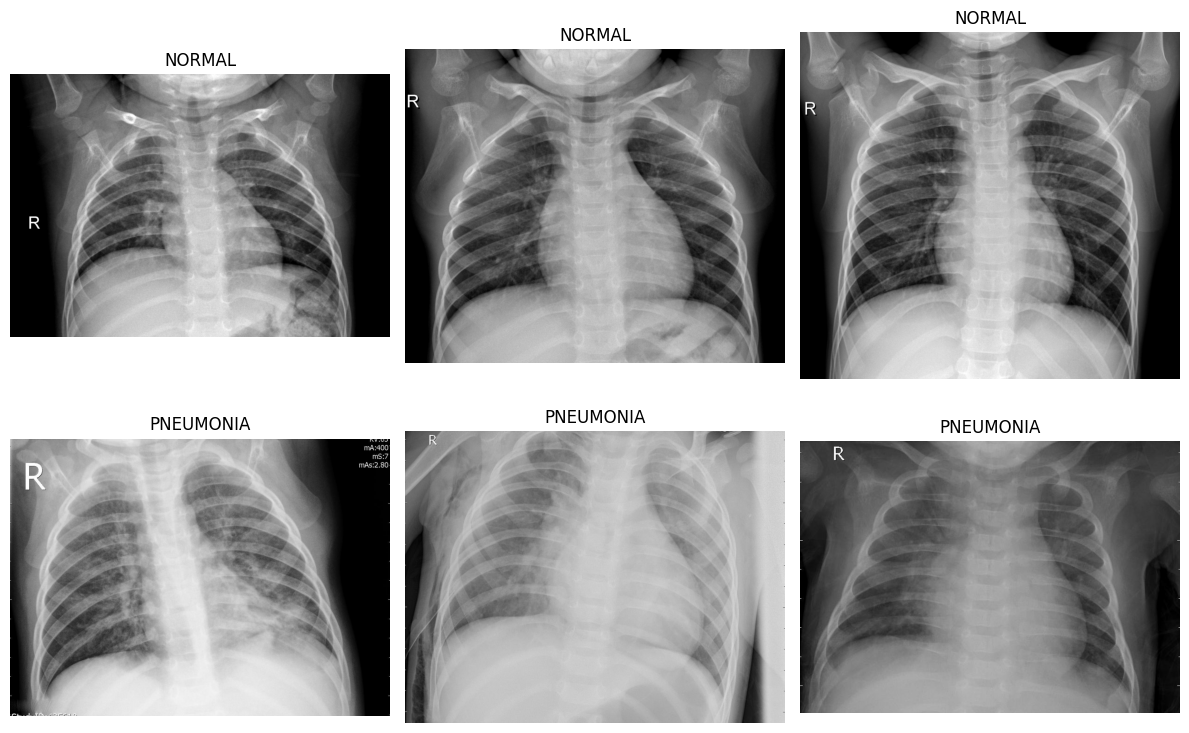

In [10]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for row, class_name in enumerate(CLASSES):
    class_dir = TRAIN_DIR / class_name

    images = [
        p for p in class_dir.iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected_images = random.sample(images, min(3, len(images)))

    for col, image_path in enumerate(selected_images):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [12]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

print("Classes :", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes : ['NORMAL', 'PNEUMONIA']


In [13]:
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_mobilenet(images, labels):
    images = preprocess_input(images)
    return images, labels

train_ds_mobilenet = (
    train_ds
    .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_ds_mobilenet = (
    val_ds
    .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_ds_mobilenet = (
    test_ds
    .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

print("Pipelines MobileNetV2 créés.")

Pipelines MobileNetV2 créés.


In [14]:
for images, labels in train_ds_mobilenet.take(1):
    print("Forme des images :", images.shape)
    print("Forme des labels :", labels.shape)
    print("Valeur minimale :", float(tf.reduce_min(images)))
    print("Valeur maximale :", float(tf.reduce_max(images)))

print("\nGPU détecté :", tf.config.list_physical_devices("GPU"))

Forme des images : (32, 224, 224, 3)
Forme des labels : (32, 1)
Valeur minimale : -1.0
Valeur maximale : 1.0

GPU détecté : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
